# TIME-INDEPENDENT SCHRODINGER EQUATION FOR PARTICLE IN A BOX

In [209]:
from matplotlib import pyplot as plt
import numpy as np
import scipy
from matplotlib.animation import PillowWriter

## Solve

$$ H \psi = E \psi, \quad -1 \leq x \leq 1, \quad \psi (-1) = \psi(1)  = 0  $$

$$ V = \begin{cases}
 V_0 && -1 \leq x \leq 1/2 \\
 0, && -1/2 \leq x \leq 1/2 \\
 V_0 && 1/2 \leq x \leq 1
\end{cases}$$




Things to consider:

1) For each choice of $V_0$, there are infinite solutions/eigen values $E$. But the numerics is limited by the grid spacing $dx$. Hence one should not trust eigen value-vector pairs past $n=10$ or so

2) Solutions $E_n> V_0$ are continuum states. $E_n < V_0$ are bound states. We have the analytical solutions for bound states. Furthermore the boundary conditions used are only for bound states so we will only focus on those. So $V_0$ should be picked decently large such that the eigen modes one wants to display are bound, and that the strict Dirichlet conditions make sense.

3) As $V_0 \rightarrow \infty$, more and more states become bound. We recover the infinite square well spectrum.


time-dependent movie with crank nicholson, simple superposition versus gaussian packet:  gauss-legendre to check normalization

hydrogen atom with 2 electrons

In [182]:
hbar = 1.
m = 1.
L = 1.
V0 = 10*(np.pi**2)/2 #En = n^2*pi^2/2 for infinite square well, n=1,2,3,4...... 100 to 1000 is a good range to see enough bound states, and visibly see tails get weaker as potential is increased.

In [131]:
dx  = 0.01 #k = n pi/L, lambda = 2 pi/k = 2 L/n. So can trust 10-20 eigen modes

x = np.linspace(-1 + dx, 1 - dx, int((2 - 2*dx)/dx + 1))

In [183]:

def create_hamiltonian():
    H = np.zeros((len(x), len(x)))
    
    for i in range(0, len(x)):
        if i == 0:

            H[0,0] = -2.*(-hbar**2/(2*m))/dx**2 + V0
            H[0,1] = 1.*(-hbar**2/(2*m))/dx**2
        elif i == len(x)-1:
            H[len(x)-1,len(x)-1] = -2.*(-hbar**2/(2*m))/dx**2 + V0
            H[len(x)-1, len(x)-2] = 1.*(-hbar**2/(2*m))/dx**2
        else:
            if -0.5<x[i]<0.5:
                H[i,i] = -2.*(-hbar**2/(2*m)) /dx**2
                H[i,i-1] = 1.*(-hbar**2/(2*m))/dx**2
                H[i,i+1] = 1.*(-hbar**2/(2*m))/dx**2
            else:
                H[i,i] = -2.*(-hbar**2/(2*m))/dx**2 + V0
                H[i,i-1] = 1.*(-hbar**2/(2*m))/dx**2
                H[i,i+1] = 1.*(-hbar**2/(2*m))/dx**2
    
    E, psi = scipy.linalg.eigh(H)
    
  

    for i in range(0, len(psi)): #need to change the normalization so that the integral (and not the p2 norm) is 1.

        psi[:,i] = psi[:,i]/np.sqrt(np.sum(np.abs(psi[:,i])**2) * dx)

        
    return E, psi
    

In [184]:
E, psi = create_hamiltonian()

## Plot Eigen Values

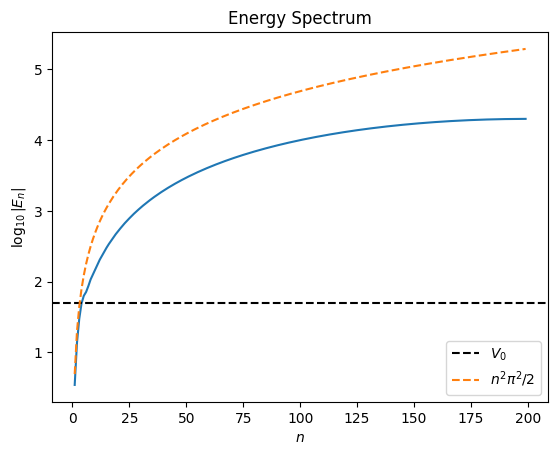

In [185]:
plt.plot(np.arange(1,len(x)+1, dtype = np.float64),  np.log10(E))
plt.axhline(y = np.log10(V0), c='black', linestyle='dashed', label =r'$V_0$')
plt.plot(np.arange(1,len(x)+1, dtype = np.float64), np.log10(np.pi**2/2) + 2*np.log10(np.arange(1,len(x)+1, dtype = np.float64)), linestyle='dashed', label =r'$n^2 \pi^2/2$')
plt.ylabel(r'$\log_{10}|E_n|$')
plt.xlabel(r'$n$')
plt.title('Energy Spectrum')
plt.legend(loc=4)
plt.show()

Observations:

1. $n^2$ behaviour is retained for low modes.
2. $n^2$ behaviour breaks when $E_n \geq V_0$, because the bound boundary conditions seize making sense for continuum states.

## Plot Eigen Modes

In [186]:
def analytical_finite_square_well(n):
    kappa = np.sqrt(2*m*(V0-E[n])/hbar**2)
    k = np.sqrt(2*m*E[n]/hbar**2)
    if n%2 == 0: #even parity
        B = (L/2 + np.sin(k*L)/(2*k) + np.cos(k*L/2)**2./kappa)**(-1./2.)
        C = B*np.cos(k*L/2)*np.exp(kappa*L/2)
        x_left = np.linspace(-L, -L/2, 1000)
        x_mid = np.linspace(-L/2, L/2, 1000)
        x_right = np.linspace(L/2, L, 1000)
        psi_left = C*np.exp(kappa*x_left)
        psi_mid = B*np.cos(k*x_mid)
        psi_right = C*np.exp(-kappa*x_right)
        return np.concatenate((x_left, x_mid, x_right)), np.concatenate((psi_left, psi_mid, psi_right))
        
    elif n%2 != 0: #odd parity
        B = (L/2 - np.sin(k*L)/(2*k) + np.sin(k*L/2)**2./kappa)**(-1./2.)
        C = -B*np.sin(k*L/2)*np.exp(kappa*L/2)
        x_left = np.linspace(-L, -L/2, 1000)
        x_mid = np.linspace(-L/2, L/2, 1000)
        x_right = np.linspace(L/2, L, 1000)
        psi_left = C*np.exp(kappa*x_left)
        psi_mid = B*np.sin(k*x_mid)
        psi_right = -C*np.exp(-kappa*x_right)
        return np.concatenate((x_left, x_mid, x_right)), np.concatenate((psi_left, psi_mid, psi_right))






In [187]:



def analytical_infinite_square_well(n):
    x_left = np.linspace(-L, -L/2, 1000)
    x_mid = np.linspace(-L/2, L/2, 1000)
    x_right = np.linspace(L/2, L, 1000)
   
    C2 = np.sqrt(2/L)
    return  np.concatenate((x_left, x_mid, x_right)), np.concatenate( (np.zeros(1000), C2*np.sin(n*np.pi*x_mid/L + n*np.pi/2),np.zeros(1000))) #n=1,2,3,.....
    # C2*np.cos((2*n+1)*np.pi*x/L) #n=0,1,2,.....
    #C2*np.sin(2*n*np.pi*x/L) #n=1,2,3,...

In [216]:
def plot_eigenvector(n, ax):

    ax.plot(x, np.abs(psi[:,n])**2, label ='Numerical', c='blue')

    #infinite square well
    analytical_infinite = analytical_infinite_square_well(n+1)
    ax.plot(analytical_infinite[0], np.abs(analytical_infinite[1])**2, c='black', linestyle='dashed', label ='Infinite square well')

    #finite square well
    analytical_finite = analytical_finite_square_well(n)
    ax.plot(analytical_finite[0], np.abs(analytical_finite[1])**2, c='red', linestyle='dashed', label ='Finite square well')

    ax.legend(loc=2)

    ax.set_xlabel(r'$L$', c='white', fontsize = 20)
    ax.set_ylabel(r'$|\psi|^2$', c='white', fontsize =20)
    #plt.axvline(x = -L/2, c='black', linestyle='dashed')
    ax.axvspan(-L,-L/2, facecolor='pink',alpha=(1-0.1)*(V0*2/np.pi**2)/(1500-100))
    ax.axvspan(-L/2,L/2, facecolor='yellow',alpha=0.4)
    ax.axvspan(L/2,L, facecolor='pink',alpha=(1-0.1)*(V0*2/np.pi**2)/(1500-100))
    #plt.axvline(x = L/2, c='black', linestyle='dashed')
    ax.set_title('Ground State', c='white', fontsize = 20)
    ax.annotate( r'$V_0$ = '+str("%.3f" % V0), (-1, 1), fontsize = 10, c='black')
    ax.annotate( r'$V_0$ = '+str(0), (-0.125, 0.5), fontsize = 10, c='black')
    ax.annotate( r'$E$ = '+str("%.3f" % E[0]), (-0.125, 0.25), fontsize = 10, c='black')
    ax.annotate( r'$V_0$ = '+str("%.3f" % V0), (0.5, 1), fontsize = 10, c='black')

    


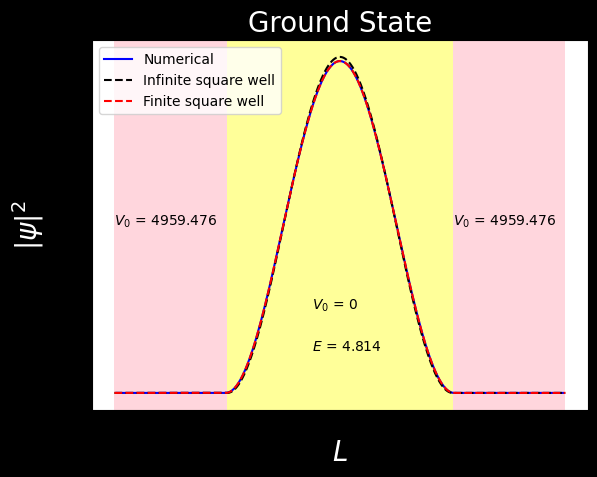

In [217]:

fig, ax = plt.subplots()
fig.patch.set_facecolor('black')
plot_eigenvector(0, ax)
plt.show()

## Make Movie

In [210]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

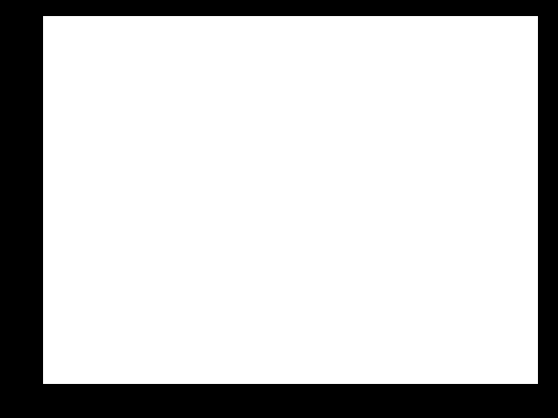

In [218]:
fig, ax = plt.subplots()
fig.patch.set_facecolor('black')

with writer.saving(fig, 'time_independent.gif',100):
    for i in range(10, 1501, 5):
            V0 = i*np.pi**2/2
            E, psi = create_hamiltonian()
            plot_eigenvector(0, ax)
            writer.grab_frame()
            ax.clear()
        

## Root Analysis (Not Used)

In [190]:
V0

49.34802200544679

In [191]:
V0-E

array([ 4.58864979e+01,  3.56915095e+01,  1.95347686e+01,  1.27511517e-01,
       -1.37782397e+01, -2.20102732e+01, -3.72543320e+01, -5.81756234e+01,
       -7.69125075e+01, -9.83551910e+01, -1.25928198e+02, -1.54724810e+02,
       -1.83426911e+02, -2.16134152e+02, -2.53134558e+02, -2.90883245e+02,
       -3.29686491e+02, -3.72510602e+02, -4.18697102e+02, -4.65681228e+02,
       -5.14301787e+02, -5.66742536e+02, -6.22018283e+02, -6.78210026e+02,
       -7.36344976e+02, -7.98072359e+02, -8.62293630e+02, -9.27534628e+02,
       -9.94880407e+02, -1.06559987e+03, -1.13856581e+03, -1.21262565e+03,
       -1.28886736e+03, -1.36827750e+03, -1.44973673e+03, -1.53233469e+03,
       -1.61713798e+03, -1.70491572e+03, -1.79457262e+03, -1.88538714e+03,
       -1.97839382e+03, -2.07418902e+03, -2.17170848e+03, -2.27038212e+03,
       -2.37120814e+03, -2.47464199e+03, -2.57965299e+03, -2.68579559e+03,
       -2.79403044e+03, -2.90469547e+03, -3.01679402e+03, -3.12998508e+03,
       -3.24519211e+03, -

Even parity finite square well for bound states satisfy

$$ \kappa/k = tan(kL/2), \quad \kappa = \sqrt{(2m(V-E))/\hbar^2}, \quad k = \sqrt{(2mE)/\hbar^2}$$

Odd parity finite square well for bound states satisfy

$$ -k/\kappa = tan(kL/2) $$

C:\Users\Ayush Roy\AppData\Local\Temp\ipykernel_26724\3860321925.py:2: RuntimeWarning: invalid value encountered in sqrt
  kappa = np.sqrt(2*m*(V0-E_plot)/hbar**2)


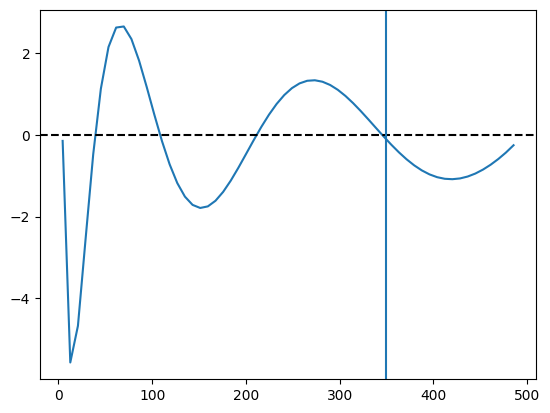

In [358]:
def plot_finite_square_well_root(E_plot):
    kappa = np.sqrt(2*m*(V0-E_plot)/hbar**2)
    k = np.sqrt(2*m*E_plot/hbar**2)
    #print(np.cos(k*L/2)*(kappa/k) - np.sin(k*L/2))
    plt.plot(E_plot, np.cos(k*L/2)*(kappa/k) - np.sin(k*L/2))
    plt.axhline(y=0, c='black', linestyle='dashed')
    plt.axvline(x=E[8])
    #plt.ylim([-1,1])
    plt.show()

plot_finite_square_well_root(np.linspace(E[0],E[20],100))